# **Esteira de aprendizado de máquina: Classificação de Músicas Virais**

## Etapa 1: escolha do dataset

O dataset escolhido foi "What Makes a Song Viral?", disponível em: https://www.kaggle.com/datasets/vedauv/what-makes-a-song-go-viral-10000-tracks/data?select=viral_songs.csv.
No problema de classificação binária, é preciso identificar se uma música será viral ou não viral (a coluna target é "viral").

In [1]:
!pip install pandas seaborn matplotlib scikit-learn scipy

  Using cached matplotlib-3.10.9-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (52 kB)
  Using cached scikit_learn-1.7.2-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (11 kB)
  Using cached scipy-1.15.3-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
  Using cached contourpy-1.3.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.65.0-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (125 kB)
  Using cached kiwisolver-1.5.1-cp310-cp310-manylinux_2_12_x86_64.manylinux2010_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp310-cp310-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
Using cached matplotlib-3.10.9-cp310-cp310-manylinu

In [2]:
import io
import os
import math
import numpy as np # operações matemáticas
import pandas as pd # permite trabalhar com DataFrame
import seaborn as sns # visualização gráfica
import matplotlib.pyplot as plt # visualização gráfica
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, roc_curve, auc, confusion_matrix,
    precision_recall_curve, classification_report, f1_score,
)

## Etapa 2: importar o dataset

In [3]:
df = pd.read_csv('viral_songs.csv')

## Etapa 3: estatísticas descritivas sobre o dataset

In [4]:
df.shape # quantidade de linhas e colunas (ou seja, quantidade de registros e de atributos)

(10000, 17)

In [5]:
df.head(10) # exibe os primeiros 10 registros

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1
5,track_00006,Track_00006,Artist_1035,Electronic,2016,262,0.867,0.915,0.774,133.1,0.586,0.000,0.048,0.173,-12.26,1212070,1
6,track_00007,Track_00007,Artist_0408,Jazz,2010,258,0.677,0.388,0.429,102.5,0.687,0.216,0.038,0.242,-7.71,53072,0
7,track_00008,Track_00008,Artist_0920,Electronic,2023,108,0.903,0.785,0.152,133.2,0.021,0.092,0.116,0.160,-7.36,2602316,0
8,track_00009,Track_00009,Artist_1555,Pop,2018,247,0.470,0.717,0.659,154.9,0.121,0.210,0.077,0.040,-4.57,384920,1
9,track_00010,Track_00010,Artist_0697,Latin,2015,191,0.969,0.917,0.648,106.2,0.076,0.335,0.217,0.285,-7.97,155044,1


In [8]:
df.info() # detalha mais sobre as colunas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          10000 non-null  object 
 1   track_name        10000 non-null  object 
 2   artist            10000 non-null  object 
 3   genre             10000 non-null  object 
 4   release_year      10000 non-null  int64  
 5   duration_sec      10000 non-null  int64  
 6   danceability      10000 non-null  float64
 7   energy            10000 non-null  float64
 8   valence           10000 non-null  float64
 9   tempo_bpm         10000 non-null  float64
 10  acousticness      10000 non-null  float64
 11  instrumentalness  10000 non-null  float64
 12  speechiness       10000 non-null  float64
 13  liveness          10000 non-null  float64
 14  loudness_db       10000 non-null  float64
 15  streams           10000 non-null  int64  
 16  viral             10000 non-null  int64  

In [9]:
df.describe() # estatísticas sobre todas as colunas, como média, mediana, quartis

,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,1.000000e+04,10000.00000
mean,2017.499400,208.776800,0.611709,0.651938,0.582280,110.975940,0.295583,0.177337,0.087453,0.184925,-7.975896,2.415685e+06,0.36050
std,4.607854,49.967024,0.192612,0.187686,0.177984,19.017206,0.263574,0.161221,0.069674,0.114307,2.976277,9.721026e+06,0.48017
min,2010.000000,60.000000,0.000000,0.005000,0.000000,50.000000,0.000000,0.000000,0.000000,0.000000,-18.740000,1.340000e+02,0.00000
25%,2013.000000,175.000000,0.482000,0.529000,0.459000,98.000000,0.085000,0.017000,0.027000,0.099000,-9.980000,8.671450e+04,0.00000
50%,2018.000000,209.000000,0.624000,0.669000,0.582000,111.300000,0.235000,0.154000,0.080000,0.180000,-7.980000,3.290580e+05,0.00000
75%,2022.000000,242.000000,0.753000,0.787000,0.703000,124.500000,0.441000,0.288000,0.134000,0.264000,-5.990000,1.343092e+06,1.00000
max,2025.000000,433.000000,1.000000,1.000000,1.000000,177.800000,1.000000,0.934000,0.381000,0.623000,0.000000,4.430683e+08,1.00000


In [10]:
df.describe(include='object')  # estatísticas das colunas de texto (quantidade de valores distintos, mais frequente)

,track_id,track_name,artist,genre
count,10000,10000,10000,10000
unique,10000,10000,1987,10
top,track_00001,Track_00001,Artist_0796,Rock
freq,1,1,15,1084


viral
0    6395
1    3605
Name: count, dtype: int64
viral
0    63.95
1    36.05
Name: proportion, dtype: float64


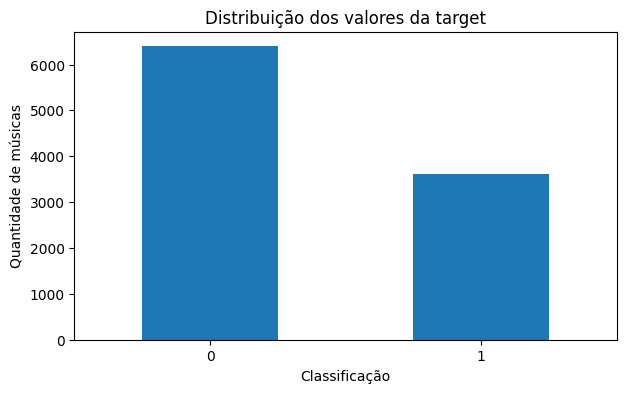

In [11]:
print(df['viral'].value_counts()) # os valores de labels do problema de classificação
print(df['viral'].value_counts(normalize=True) * 100) # verificar desbalanceamento das classes
df['viral'].value_counts().plot(kind='bar',figsize=(7, 4), rot=0)
plt.title('Distribuição dos valores da target')
plt.xlabel('Classificação')
plt.ylabel('Quantidade de músicas')
plt.show()

## Etapa 4: gráficos de densidade

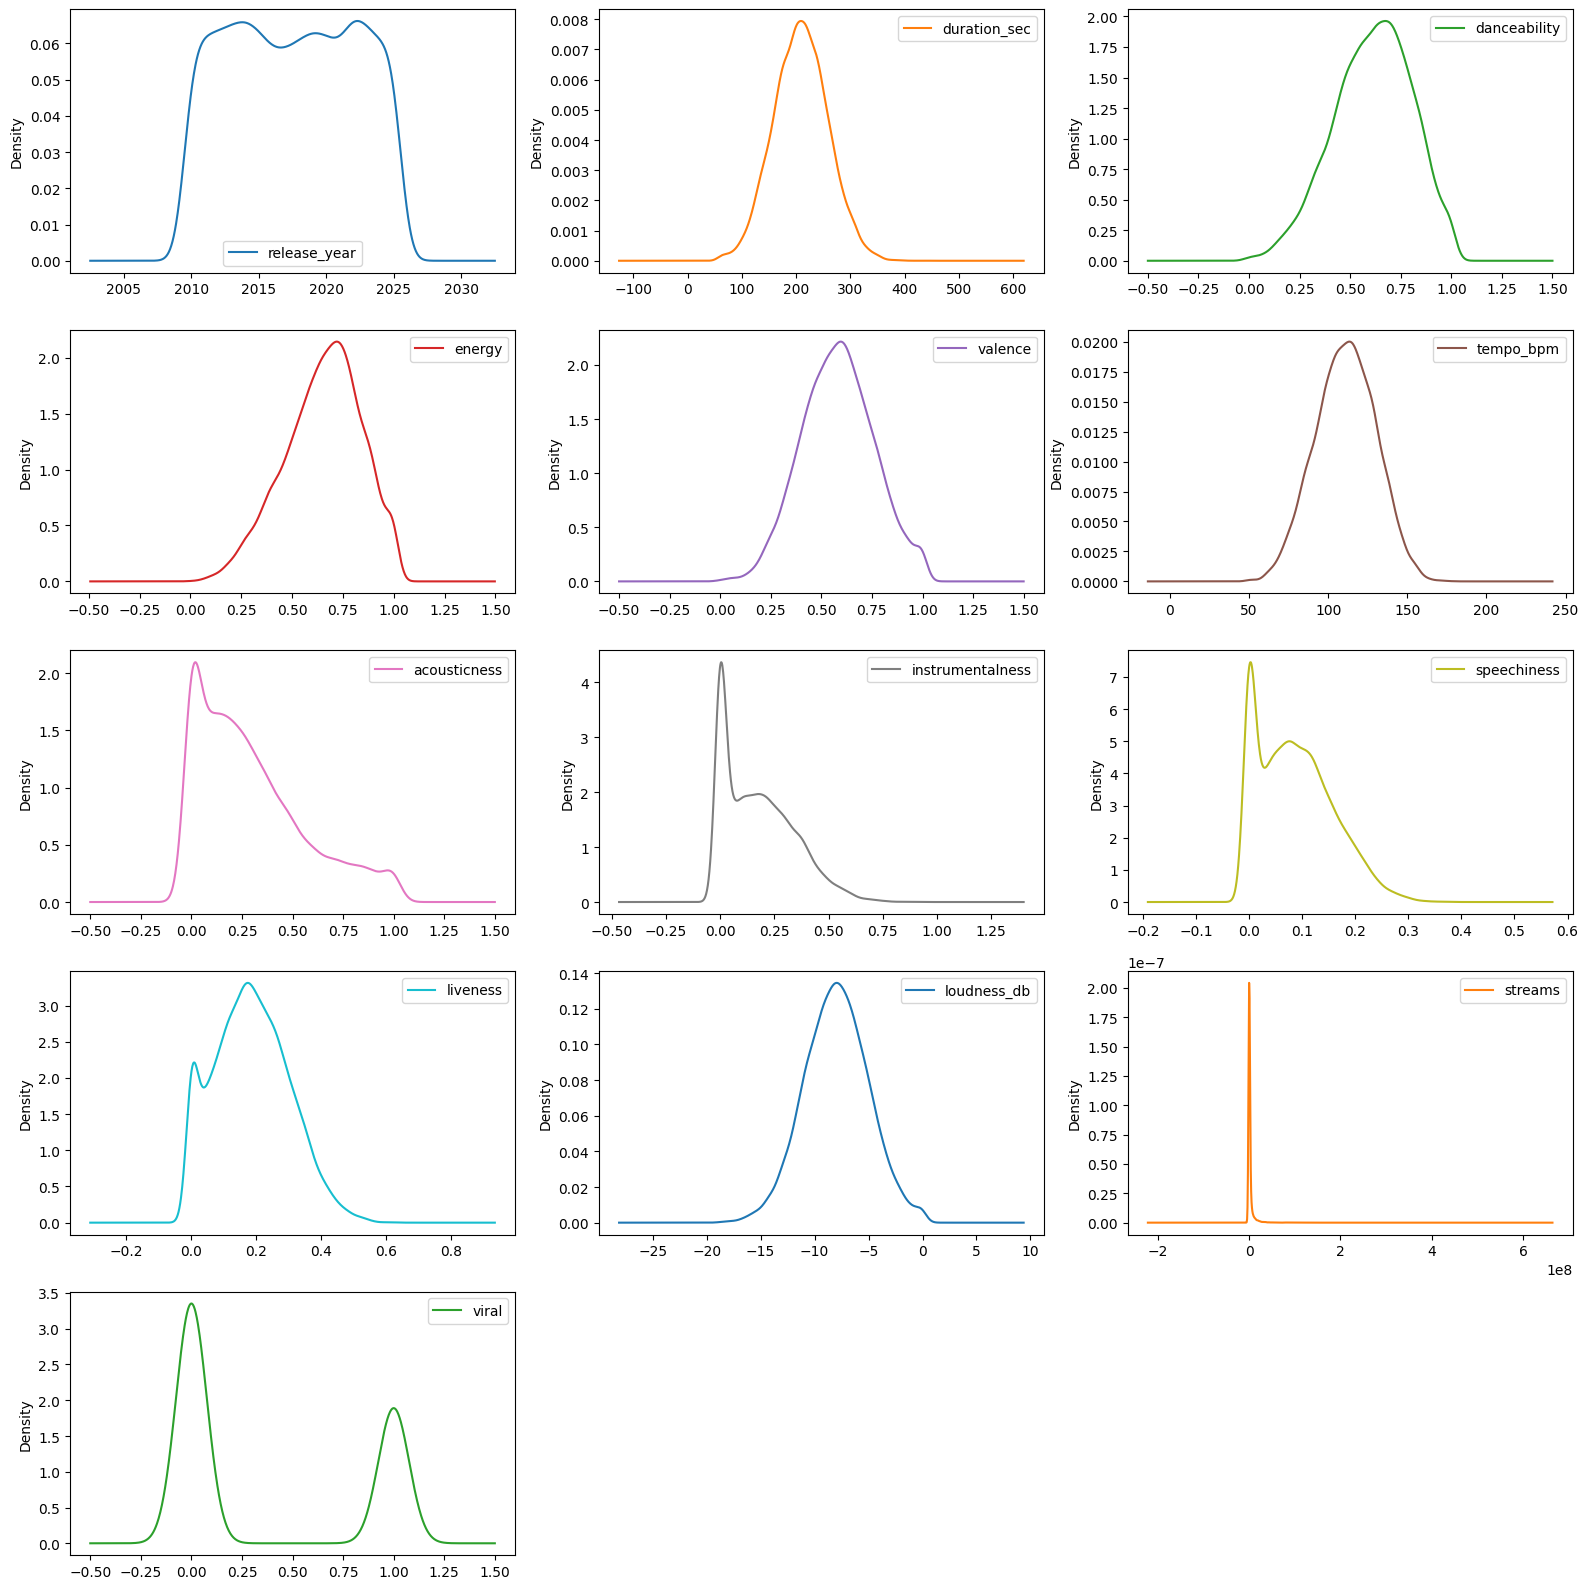

In [12]:
# gráficos de densidade
colunas_plot = df.select_dtypes(include='number').columns.tolist() # apenas inteiros e decimais
linhas_plot = math.ceil(len(colunas_plot) / 3)
df[colunas_plot].plot(kind='density', subplots=True, layout=(linhas_plot, 3),
                      figsize=(16, 3.2 * linhas_plot), sharex=False)
plt.tight_layout()
plt.show()

## Etapa 5: tratamento de dados

### Parte 1: transformação nas linhas

Eliminar linhas de valores ausentes, duplicados ou inválidos. Por exemplo, remover músicas que possuem o mesmo track_id.

In [15]:
linhas_antes = len(df)
df = df.dropna() # excluir linhas que possuem valores nulos
df = df.drop_duplicates(subset='track_id'); # remover ids duplicados
df = df.drop_duplicates() # excluir linhas duplicadas

regras = {
    'duração inválida': df['duration_sec'] <= 0,
    'bpm inválido': df['tempo_bpm'] <= 0, # bpm negativo
    'viral fora de 0 e 1': ~df['viral'].isin([0,1]) # classificação não é 0 ou 1
}
# criar outras regras para as colunas de escala 0 a 1
colunas_escala_0_a_1 = ['danceability', 'energy', 'valence', 'acousticness', 'instrumentalness', 'speechiness', 'liveness']
for coluna in colunas_escala_0_a_1:
  if coluna not in df.columns:
    continue
  regras[f"registro de {coluna} fora de [0,1]"] = ~df[coluna].between(0,1)

registros_invalidos = pd.Series(False, index=df.index)
for nome, condicao in regras.items():
    print(f"{nome}: {int(condicao.sum())} linhas")
    registros_invalidos |= condicao

df = df[~registros_invalidos].reset_index(drop=True)

print(f'Quantidade de linhas antes: {linhas_antes}. Linhas restantes {len(df)}')

duração inválida: 0 linhas
bpm inválido: 0 linhas
viral fora de 0 e 1: 0 linhas
registro de danceability fora de [0,1]: 0 linhas
registro de energy fora de [0,1]: 0 linhas
registro de valence fora de [0,1]: 0 linhas
registro de acousticness fora de [0,1]: 0 linhas
registro de instrumentalness fora de [0,1]: 0 linhas
registro de speechiness fora de [0,1]: 0 linhas
registro de liveness fora de [0,1]: 0 linhas
Quantidade de linhas antes: 10000. Linhas restantes 10000


### Parte 2: transformação nas colunas

1. As colunas track_id e track_name identificam a música, mas não ajudam a prever target.
2. A coluna genre é string e deve ser convertida para um valor numérico. É possível realizar one-hot-enconding em genre porque possui poucos valores diferentes.
3. A coluna artist também é string, porém possui milhares de registros diferentes, impossibilitando one-hot-encondig. Portanto, será removida.
3. A coluna stream é utilizada no dataset para problemas de regressão. No problema de classificação, ela entrega a resposta.

In [16]:
colunas_remover = ['track_id', 'track_name', 'streams', 'artist']
df = df.drop(columns=[col for col in colunas_remover if col in df.columns])
df['viral'] = df['viral'].astype(int)
df.head()

,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,viral
0,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,1
1,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1
2,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,1
3,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,0
4,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,1


In [17]:
# convertendo usando One-Hot-Enconding, já que não queremos correr o risco de adicionar uma "ordem" entre os gêneros.
# cada gênero vira coluna de valores 0 a 1
print(df['genre'].value_counts())
df = pd.get_dummies(df,columns=['genre'], dtype='int8', drop_first=False)
df.head(10)

genre
Rock          1084
Hip-Hop       1052
Latin         1030
Pop           1002
Indie          993
Electronic     991
Classical      991
Jazz           965
R&B            950
Country        942
Name: count, dtype: int64


,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,...,genre_Classical,genre_Country,genre_Electronic,genre_Hip-Hop,genre_Indie,genre_Jazz,genre_Latin,genre_Pop,genre_R&B,genre_Rock
0,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,...,0,0,0,0,0,0,0,1,0,0
1,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,...,0,0,1,0,0,0,0,0,0,0
2,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,...,0,0,0,1,0,0,0,0,0,0
3,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,...,1,0,0,0,0,0,0,0,0,0
4,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,...,0,0,0,0,0,0,0,1,0,0
5,2016,262,0.867,0.915,0.774,133.1,0.586,0.000,0.048,0.173,...,0,0,1,0,0,0,0,0,0,0
6,2010,258,0.677,0.388,0.429,102.5,0.687,0.216,0.038,0.242,...,0,0,0,0,0,1,0,0,0,0
7,2023,108,0.903,0.785,0.152,133.2,0.021,0.092,0.116,0.160,...,0,0,1,0,0,0,0,0,0,0
8,2018,247,0.470,0.717,0.659,154.9,0.121,0.210,0.077,0.040,...,0,0,0,0,0,0,0,1,0,0
9,2015,191,0.969,0.917,0.648,106.2,0.076,0.335,0.217,0.285,...,0,0,0,0,0,0,1,0,0,0


## Etapa 6: matriz de correlação


Investiga relacionamentos lineares entre variáveis, de 1 a -1: próximo de 1 indica uma relação linear positiva, próxima de -1 uma relação linear negativa, e próxima de 0 uma relação pequena ou inexistente.

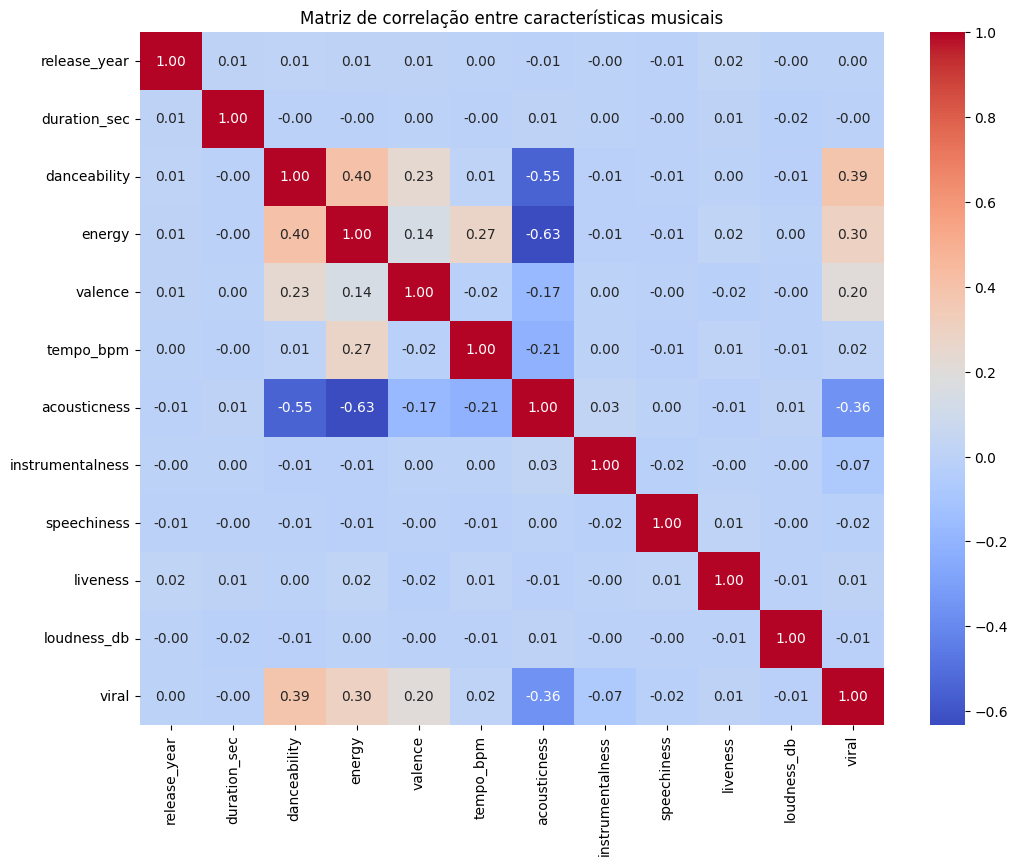

In [18]:
# deixar as colunas de gênero de fora
colunas_numericas = [c for c in df.columns if not c.startswith('genre_')]
matriz_correlacao = df[colunas_numericas].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(matriz_correlacao, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de correlação entre características musicais')
plt.show()

## Etapa 7: criar subcojuntos de dados (treinamento, testes e validação)

In [20]:
target_column = 'viral' # define a target
# para usar o algoritmo xgboost, é preciso reordenar de forma que a target seja a primeira coluna
feature_cols = [col for col in df.columns if col != target_column]
df = df[[target_column] + feature_cols]
df.head()

,viral,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,...,genre_Classical,genre_Country,genre_Electronic,genre_Hip-Hop,genre_Indie,genre_Jazz,genre_Latin,genre_Pop,genre_R&B,genre_Rock
0,1,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,...,0,0,0,0,0,0,0,1,0,0
1,1,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,...,0,0,1,0,0,0,0,0,0,0
2,1,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,...,0,0,0,1,0,0,0,0,0,0
3,0,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,...,1,0,0,0,0,0,0,0,0,0
4,1,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,...,0,0,0,0,0,0,0,1,0,0


In [21]:
# separação em 80% para treinamento, 10% para teste e 10% para validação
train, restante = train_test_split(df, test_size=0.2, random_state=42, stratify=df[target_column]) # separa primeiro em 2 grupos, com 20% para test_and_validate
test, validate = train_test_split(restante, test_size=0.5, random_state=42, stratify=restante[target_column]) # separa novamente

In [22]:
print("treinamento:", train.shape)
print("teste:", test.shape)
print("validação:", validate.shape)

treinamento: (8000, 22)
teste: (1000, 22)
validação: (1000, 22)


In [23]:
# verificar proporção entre "viral" e "não viral" em cada divisão:
t1 = train[target_column].value_counts()
t2 = validate[target_column].value_counts()
t3 = test[target_column].value_counts()
distribuicao = pd.concat(
    [t1, t2, t3],
    axis=1
)
distribuicao.columns = ['Treinamento','Validação', 'Teste']
distribuicao.index.name = 'Classificação'
display((distribuicao / distribuicao.sum() * 100).round(2))  # em porcentagem

,Treinamento,Validação,Teste
Classificação,,,
0,63.95,64.0,63.9
1,36.05,36.0,36.1


## Etapa 8: treinamento no algoritmo xgboost

Nessa etapa, enviamos os dados como csv para o S3.

In [24]:
import boto3
import sagemaker
from sagemaker.image_uris import retrieve
print("Versão sdk do sagemaker: ", sagemaker.__version__)
print("Região da AWS: ", boto3.Session().region_name)

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/ec2-user/.config/sagemaker/config.yaml
Versão sdk do sagemaker:  2.189.0
Região da AWS:  us-east-1


In [25]:
boto_session = boto3.Session()
s3_resource = boto_session.resource('s3')
s3_client = boto_session.client('s3')
region = boto_session.region_name
sagemaker_session = sagemaker.Session(boto_session=boto_session)
role = sagemaker.get_execution_role()
bucket='c232372a5850161l18273834t1w975050161290-labbucket-shyyyp1sapet'
prefix = "pipeline-viral-songs"

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/ec2-user/.config/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/ec2-user/.config/sagemaker/config.yaml


In [26]:
# função que manda o df para o s3 como .csv, sem cabeçalho ou índice
def upload_s3_csv(filename, folder, dataframe):
    csv_buffer = io.StringIO()
    dataframe.to_csv(csv_buffer, header=False, index=False)
    s3_resource.Bucket(bucket).Object(os.path.join(prefix, folder, filename)).put(Body=csv_buffer.getvalue())

In [27]:
upload_s3_csv('viral_train.csv', 'train', train)
upload_s3_csv('viral_validate.csv', 'validate', validate)

É preciso definir os hiperparâmetros do algoritmo XGBoost:

*   objetive: "binary:logistic": classificação binária pois target vale 0 ou 1.
*   eval_metric: "auc": usa a área sob a curva ROC para validação.
* num_round e early_stopping_rounds: até 200 rodadas, parando quando a métrica AUC como validação não melhora a 20 rodadas.

In [28]:
nao_virais = int((train[target_column] == 0).sum())
virais = int((train[target_column] == 1).sum())
razao = nao_virais / virais if virais > 0 else 1.0
scale_pos_weight = round(razao, 2) if razao >= 1.5 else 1.0

hyperparams = {
    "objective": "binary:logistic",
    "num_round":"200",
    "eval_metric": "auc",
    "early_stopping_rounds": "20",
    "scale_pos_weight": str(scale_pos_weight)
}

In [29]:
container = retrieve(framework='xgboost',region=region, version='1.7-1')
s3_output_location = f"s3://{bucket}/{prefix}/output/"

# xgboost
xgb_model = sagemaker.estimator.Estimator(
    image_uri=container,
    role=role,
    instance_count=1,
    instance_type='ml.m4.xlarge',
    output_path=s3_output_location,
    hyperparameters=hyperparams,
    sagemaker_session=sagemaker_session
)

In [30]:
train_channel = sagemaker.inputs.TrainingInput(
    s3_data=f"s3://{bucket}/{prefix}/train/",
    content_type='text/csv'
)

validate_channel = sagemaker.inputs.TrainingInput(
    s3_data=f"s3://{bucket}/{prefix}/validate/",
    content_type='text/csv'
)

data_channels = {'train': train_channel, 'validation': validate_channel}

In [31]:
xgb_model.fit(inputs=data_channels, logs=True)

INFO:sagemaker:Creating training-job with name: sagemaker-xgboost-2026-11-22-18-51-05-419


2026-11-22 18:51:05 Starting - Starting the training job...
2026-11-22 18:51:21 Starting - Preparing the instances for training...
2026-11-22 18:51:55 Downloading - Downloading input data...
2026-11-22 18:52:35 Downloading - Downloading the training image......
2026-11-22 18:53:31 Training - Training image download completed. Training in progress....
2026-11-22 18:53:56 Uploading - Uploading generated training model...
2026-11-22 18:54:09 Completed - Training job completed
..Training seconds: 134
Billable seconds: 134


## Etapa 9: Implamantar modelo

O modelo pode ser usado de duas formas:
* inferência em lote: envia o arquivo com muitas músicas de uma vez e recebe todas as probabilidades. Será usada para os conjuntos de validação e de teste.
* inferência em tempo real: um endpoint ativo que responde com a probabilidade de uma música por vez.


### Batch Transform

In [32]:
X_validate = validate[feature_cols] # possui apenas as características
y_validate = validate[target_column].to_numpy() # target

X_test = test[feature_cols] # possui apenas as características
y_test = test[target_column].to_numpy() # target

In [33]:
# enviar validate e test com apenas as características para o S3
upload_s3_csv('viral_validate_features.csv', 'validation-input', X_validate)
upload_s3_csv('viral_test_features.csv','test-input', X_test)

In [34]:
# função que realiza batch transform no s3 e devolve o caminho com as probabilidades
def batch_predict(input_folder, filename, output_folder):
  transformer = xgb_model.transformer(
    instance_count=1,
    instance_type='ml.m4.xlarge',
    strategy='MultiRecord',
    assemble_with='Line',
    output_path=f's3://{bucket}/{prefix}/{output_folder}/'
  )

  input_path = f's3://{bucket}/{prefix}/{input_folder}/{filename}'

  transformer.transform(
    data=input_path,
    data_type='S3Prefix',
    content_type='text/csv',
    split_type='Line'
  )
  transformer.wait()
  return f'{prefix}/{output_folder}/{filename}.out'

validation_output_key = batch_predict(
    'validation-input',
    'viral_validate_features.csv',
    'validation-output'
)
test_output_key = batch_predict(
    'test-input',
    'viral_test_features.csv',
    'test-output'
)

INFO:sagemaker:Creating model with name: sagemaker-xgboost-2026-11-22-18-54-47-274
INFO:sagemaker:Creating transform job with name: sagemaker-xgboost-2026-11-22-18-54-47-696


.......................................
...

INFO:sagemaker:Creating model with name: sagemaker-xgboost-2026-11-22-19-01-50-425
INFO:sagemaker:Creating transform job with name: sagemaker-xgboost-2026-11-22-19-01-50-830


.......................................
...

In [35]:
# ler arquivo de saída do batch transform
def read_predictions(output_key):
    obj = s3_client.get_object(Bucket=bucket, Key=output_key)
    predictions = pd.read_csv(io.BytesIO(obj['Body'].read()), header=None, names=['viral_predicted'])
    return predictions.iloc[:, 0].astype(float).to_numpy()

# lista de probabilidades de validate e de test
val_prob = read_predictions(validation_output_key) # validação
test_prob = read_predictions(test_output_key) # teste

print("Validação:", len(val_prob), "previsões para", len(y_validate), "músicas")
print("Teste:", len(test_prob), "previsões para", len(y_test), "músicas")

Validação: 1000 previsões para 1000 músicas
Teste: 1000 previsões para 1000 músicas


## Etapa 10: avaliação do modelo treinado

### Matriz de Confusão

In [46]:
# repostas reais
test_labels = pd.Series(y_test, name='viral_real')

# estimativa para cada música, um valor float entre 0 e 1
target_predicted = pd.DataFrame({'viral_predicted': test_prob})

# classificação binária depois de aplicar threshold
target_predicted_binary = pd.DataFrame({
    'viral_predicted': (target_predicted['viral_predicted'] >= 0.6).astype(int)
})

comparacao = pd.DataFrame({
    'real': test_labels,
    'probabilidade': target_predicted['viral_predicted'].round(4),
    'prevista': target_predicted_binary['viral_predicted'],
})
comparacao.head(10)

,real,probabilidade,prevista
0,0,0.7626,1
1,1,0.5383,0
2,1,0.8286,1
3,0,0.5830,0
4,1,0.1249,0
5,0,0.3627,0
6,0,0.0952,0
7,0,0.4429,0
8,1,0.5201,0
9,0,0.3940,0


,Not-Viral,Viral
Not-Viral,488,151
Viral,123,238


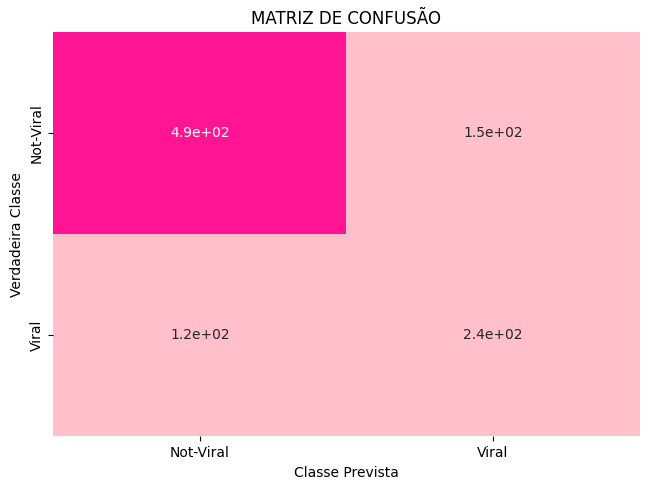

In [47]:
matrix = confusion_matrix(test_labels, target_predicted_binary['viral_predicted'], labels=[0,1])
df_confusion = pd.DataFrame(matrix, index=['Not-Viral', 'Viral'],columns=['Not-Viral', 'Viral'])
display(df_confusion)
colormap = sns.color_palette(["#FFC0CB", "#FF1493"])
sns.heatmap(df_confusion, annot=True, cbar=None, cmap=colormap)
plt.title("MATRIZ DE CONFUSÃO")
plt.tight_layout()
plt.ylabel("Verdadeira Classe")
plt.xlabel("Classe Prevista")
plt.show()

### Métricas

In [48]:
TN, FP, FN, TP = matrix.ravel()

print(f"Verdadeiros negativos (true negatives): {TN}")
print(f"Falsos positivos (false positives): {FP}")
print(f"Falsos negativos (false negatives): {FN}")
print(f"Verdadeiros positivos (true positives) : {TP}")

Verdadeiros negativos (true negatives): 488
Falsos positivos (false positives): 151
Falsos negativos (false negatives): 123
Verdadeiros positivos (true positives) : 238


In [53]:
# evitar divisão por 0
def razao(numerador, denominador):
    return float(numerador) / denominador * 100 if denominador > 0 else float('nan')

# Acurácia
ACC = razao(TP + TN, TP + TN + FP + FN)
# Sensibilidade
Sensitivity = razao(TP, TP + FN)
# Especificidade (t
Specificity = razao(TN, TN + FP)
# Precisão
Precision = razao(TP, TP + FP)

print(f"Acurácia: {ACC:.2f}% das músicas do teste foram classificadas corretamente.")
print(f"Sensibilidade: {Sensitivity:.2f}% das músicas realmente virais foram detectadas como virais.")
print(f"Especificidade: {Specificity:.2f}% das músicas realmente não virais foram detectadas como não virais.")
print(f"Precisão: quando o modelo diz que a música é viral, ele acerta em {Precision:.2f}% das vezes.")

Acurácia: 72.60% das músicas do teste foram classificadas corretamente.
Sensibilidade: 65.93% das músicas realmente virais foram detectadas como virais.
Especificidade: 76.37% das músicas realmente não virais foram detectadas como não virais.
Precisão: quando o modelo diz que a música é viral, ele acerta em 61.18% das vezes.


In [54]:
print(classification_report(test_labels, target_predicted_binary['viral_predicted'],
                            target_names=['Não viral', 'Viral'], zero_division=0))

              precision    recall  f1-score   support

   Não viral       0.80      0.76      0.78       639
       Viral       0.61      0.66      0.63       361

    accuracy                           0.73      1000
   macro avg       0.71      0.71      0.71      1000
weighted avg       0.73      0.73      0.73      1000



## Etapa 11: resultado de uma predição do modelo



O modelo é implantado em um endpoint para inferência em tempo real e recebe as características de uma música do conjunto de teste.

In [51]:
from sagemaker.serializers import CSVSerializer
from sagemaker.deserializers import CSVDeserializer

xgb_predictor = xgb_model.deploy(
    initial_instance_count=1,
    instance_type='ml.m5.large',
    serializer=CSVSerializer(),
    deserializer=CSVDeserializer()
)

INFO:sagemaker:Creating model with name: sagemaker-xgboost-2026-11-22-19-35-02-389
INFO:sagemaker:Creating endpoint-config with name sagemaker-xgboost-2026-11-22-19-35-02-389
INFO:sagemaker:Creating endpoint with name sagemaker-xgboost-2026-11-22-19-35-02-389


-------!

In [56]:
# primeira música do conjunto de teste; envia somente as características
row = X_test.iloc[[5]]
response = xgb_predictor.predict(row.to_numpy())

probability = float(np.asarray(response).ravel()[0])
classificacao_prevista = int(probability >= 0.5) # aplicar threshold

print("Probabilidade de ser viral:", f"{probability:.2%}")

if classificacao_prevista == 1:
    print("A música foi classificada como VIRAL")
else:
    print("A música foi classificada como NÃO VIRAL")

classificacao_verdadeira = y_test[0]
if classificacao_verdadeira == 1:
    print("A música é viral")
else:
    print("A música é não viral")

if classificacao_verdadeira == classificacao_prevista:
  print("O modelo acertou a classificação")
else:
  print("O modelo errou a classificação")

Probabilidade de ser viral: 36.27%
A música foi classificada como NÃO VIRAL
A música é não viral
O modelo acertou a classificação
